# Developing Uncertainty Quantification Strategies in Electromagnetic Problems Involving Highly Resonant Cavities

__Salvatore Campione__, Sandia National Laboratories, Albuquerque, NM, USA

__J. Adam Stephens__, Sandia National Laboratories, Albuquerque, NM, USA

__Nevin Martin__, Sandia National Laboratories, Albuquerque, NM, USA

__Aubrey Eckert__, Sandia National Laboratories, Albuquerque, NM, USA

__Larry K. Warne__, Sandia National Laboratories, Albuquerque, NM, USA

__Gabriel Huerta__, Sandia National Laboratories, Albuquerque, NM, USA

__Robert A. Pfeiffer__, Sandia National Laboratories, Albuquerque, NM, USA

__Adam Jones__, Sandia National Laboratories, Albuquerque, NM, USA

(Campione, Stephens and Martin are joint first authors.)

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook studies the analytical bound on the shielding effectiveness of a slotted cylindrical cavity used for the sensitivity analysis of [[1]][R1]. It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes about half a minute.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import cavity_se_model as cm

SEED = 2021                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels = [r'$d$', r'$\ell_p$', r'$w$', r'$h$', r'$a$', r'$\sigma$']
qlabels = ['SE at 1 GHz (dB)', 'SE at 2 GHz (dB)', 'SE at 3 GHz (dB)', 'SE, 1-3 GHz mean (dB)']

### Summary

Campione et al. [[1]][R1] rank six slot and cavity parameters of a slotted aluminium cylinder by first- and total-order Sobol indices of a matched power-balance bound on its shielding effectiveness (SE) between 1 and 3 GHz, and find that the slot width and slot length carry almost all of the variance. We implement that closed-form bound (their Appendix A) in numpy with complex-step gradients, reproduce their one-at-a-time sweeps (Fig. 3) and Sobol indices (Fig. 2) to within the precision of reading the figures, and estimate the active subspace of the SE bound at 1, 2 and 3 GHz and of its 1–3 GHz mean from 1000 Monte Carlo samples. Each output has a dominant active direction set by the slot width ($\lambda_1/\lambda_2 = 43.1$ at 2 GHz, $\mathbf w_1 = (-0.0789, 0.3206, 0.9375, -0.0479, -0.0663, 0.0737)$ for $d, \ell_p, w, h, a, \sigma$), almost the same at every frequency, with a clear second direction (mostly the slot length) that at 1 GHz is better separated than the first ($\lambda_2/\lambda_3 = 55.0$ against $\lambda_1/\lambda_2 = 34.4$, so we take $n = 2$ there and $n = 1$ elsewhere); a cubic in the first active variable has leave-one-out $R^2 = 0.97182$ at 2 GHz.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015 [[2]][R2].

### The model

An aluminium-alloy cylinder of interior height $h$, interior radius $a$, wall thickness $d$ and wall conductivity $\sigma$ has an azimuthal slot of width $w$ and length $\ell$ midway up its side, and is illuminated by a plane wave with the electric field along the axis ([[1]][R1], Sec. 2, p. 4). The paper defines the shielding effectiveness as the ratio of the field inside the cavity to the incident field, $\mathrm{SE}(\mathbf r) = |\mathbf E_{\mathrm{cavity}}(\mathbf r)|/E_0$, in dB as $20\log_{10}\mathrm{SE}$ (Eq. (1), p. 4); positive values mean the interior field exceeds the incident field, which the resonant cavity allows.

For its sensitivity analysis (Sec. 3) the paper uses the *matched power-balance* model of its Appendix A (pp. 20–21, from its refs. [5, 8]): an upper bound on SE, valid below the slot resonance and for an electrically short slot, that treats the cavity as a uniformly distributed matched load, so it has no cavity resonances. Its Eq. (5), as printed, is

$$
\frac{\ell\,|H_0|^2\,(8/\pi^2)}{R_{\mathrm{int}}\pi^2/(\omega L\ell)^2 + G_{\mathrm{rad}}} = P_{\mathrm{rec}} = P_{\mathrm{wall}} = 2AR_S\langle|H_j|^2\rangle_A ,
$$

with $A = 2\pi a^2 + 2\pi a h$, $R_S = \sqrt{\omega\mu_0/(2\sigma)}$, $L = \mu_0\pi/\Omega_e$, $\Omega_e = \Omega + C_e$, $\Omega = 2\ln(\ell/a_{eq})$, $C_e = 2(\ln 2 - 7/3)$, $a_{eq} = 2w/\big(\pi\exp^{1+\pi d/(2w)}\big)$, $R_{\mathrm{int}} = \mathrm{Re}(Z_{\mathrm{int}})$, $Z_{\mathrm{int}} = (L/L_{\mathrm{int}}^{r})^2 Z_{\mathrm{int}}^{r}$, $Z_{\mathrm{int}}^{r} = 2Z_S/d$, $Z_S = (1+i)R_S$, $L_{\mathrm{int}}^{r} = \mu_0 w/d$, and

$$
\pi\eta_0\ell G_{\mathrm{rad}} = -\big[1+\cos(k\ell)\big] + \Big(\frac{k\ell}{2\pi}+\frac{\pi}{2k\ell}\Big)\big[\mathrm{Cin}(k\ell+\pi)-\mathrm{Cin}(\pi-k\ell)\big] + \frac{k\ell}{2}\Big[1-\Big(\frac{\pi}{k\ell}\Big)^2\Big]\big[\mathrm{Si}(k\ell+\pi)-\mathrm{Si}(\pi-k\ell)\big],
$$

where $\mathrm{Cin}(z) = \int_0^z (1-\cos u)\,du/u$ and $\mathrm{Si}(z) = \int_0^z \sin u\,du/u$ (p. 21). Then $\langle|H_j|^2\rangle_A = P_{\mathrm{rec}}/(2AR_S)$ and Eq. (6) gives the bound

$$
\mathrm{SE}_{\max} \approx 4\langle \mathrm{SE}\rangle = 4\,\frac{\langle|H_j|^2\rangle_A}{|H_0|^2}.
$$

**Quantities of interest.** Eq. (6) is a ratio of squared H-fields, so we report $10\log_{10}\mathrm{SE}_{\max}$ in dB, that is, $20\log_{10}$ of the H-field ratio (Eq. (1) is written for the E-field ratio). The paper does not print this conversion, and it is not consistent on the point: Eq. (1) (p. 4) defines SE as a field ratio converted by $20\log_{10}$, while Eq. (6) (p. 21) calls the squared ratio SE. Read literally, $20\log_{10}$ of Eq. (6) gives 47.85 dB at the nominal point at 2 GHz (printed below), outside the 0–35 dB axes of Fig. 3 (p. 28), whose curves lie near 23–24 dB there; $10\log_{10}$ gives 23.925 dB, and with it the sweeps below agree with Fig. 3. The paper computes SE at 51 equally spaced frequencies from 1 to 3 GHz and fits one surrogate per frequency (p. 8). We ship four outputs: the SE bound at 1, 2 and 3 GHz, and, as a band summary, its mean in dB over the paper's 51 frequencies. The main analysis uses **2 GHz**, the centre of the band, because every sample there is below the slot resonance, where the paper says the model applies (p. 20); at 3 GHz, 569 of the 1000 samples are above it (below). $H_0$ cancels, so the output does not depend on the incident field.

**Coding notes.** Because $L$ and $L_{\mathrm{int}}^r$ are real, $R_{\mathrm{int}} = (L/L_{\mathrm{int}}^r)^2\,2R_S/d$, which is what `cavity_se_model.py` computes. Which length the Table 1 values are is not settled by the paper. Tables 1–2 (pp. 33–34) and the Fig. 1 caption call the input the projected length $\ell_p$, while Table 3 (p. 35) and Figs. 2–3 label the same column $\ell$. The p. 4 sentence points the other way from the tables: it says that "the projected length used to setup the geometry in the simulation is computed from the formula $\ell = 2a\sin^{-1}[\ell_p/(2a)]$", so the paper derives $\ell_p$ *from* $\ell$ to build its full-wave geometry, which suggests that the slot (arc) length $\ell$ is the primary parameter. Two readings are therefore equally plausible: (i) the Table 1 values are $\ell_p$ and Eqs. (5)–(6) use the arc length $\ell$ computed from them, and (ii) the Table 1 values are the arc length $\ell$ itself, which in the code is the same as setting $\ell = \ell_p$. This data set uses (i), so that the input keeps the label $\ell_p$ of Table 1; this is our choice, not the paper's. Reading (ii) changes the nominal SE by less than 0.13 dB and $\mathbf w_1$ by less than 0.006 per entry (`check_accuracy.py`, check 5; numbers in `DATA.md`). Si and Cin are evaluated by their power series (complex-safe), which agree with `scipy.special.sici` to $8\times10^{-15}$ on the arguments used here (check 1).

**Inputs** ($m = 6$). Table 1 (p. 33) gives ranges, and Table 3 (p. 35) the same bounds for a uniform distribution and, as an alternative, normal distributions with the midpoints as means and one sixth of the range as standard deviation (p. 13). The paper's sensitivity analysis states only the ranges ("probability distributions of each parameter are not required to rank parameter sensitivity", p. 5); we take the inputs **independent and uniform** on the Table 1 ranges, and repeat the analysis for the normal alternative in a section below. The table is printed from the model's own constants.

In [2]:
print(f"{'input':6s} {'units':8s} {'lower':>6s} {'upper':>6s} {'nominal':>8s} {'normal sd':>9s}  description")
for j, n in enumerate(cm.NAMES):
    print(f'{n:6s} {cm.UNITS[j]:8s} {cm.LOWER[j]:6.2f} {cm.UPPER[j]:6.2f} {cm.NOMINAL[j]:8.2f} {cm.NORMAL_SD[j]:9.4f}  {cm.DESCRIPTIONS[j]}')
for fg in (1.0, 1.5, 2.0, 3.0):
    p = cm.parts(cm.NOMINAL, fg * 1e9)
    print(f'nominal point, {fg:.1f} GHz: SE = {p["SE_dB"][0]:.3f} dB; slot term R_int pi^2/(omega L l)^2 = {p["T_int"][0]:.4f}, '
          f'G_rad = {p["G_rad"][0]:.4f} (1/(ohm m)); k l / pi = {p["kl"][0] / np.pi:.3f}')
p = cm.parts(cm.NOMINAL, 2e9)
print(f'Eq. (6) at the nominal point, 2 GHz: 10 log10 SE_max = {p["SE_dB"][0]:.3f} dB; read literally with 20 log10 = {2 * p["SE_dB"][0]:.2f} dB')
print(f'nominal arc length l = {p["l"][0] / cm.INCH:.4f} in (l_p = 2 in); a_eq = {p["a_eq"][0]:.2e} m; Omega_e = {p["Omega_e"][0]:.2f}')

input  units     lower  upper  nominal normal sd  description
d      in         0.20   0.30     0.25    0.0167  slot depth (wall thickness)
l_p    in         1.50   2.50     2.00    0.1667  projected slot length
w      mil        5.00  25.00    15.00    3.3333  slot width
h      in        21.60  26.40    24.00    0.8000  cavity interior height
a      in         3.60   4.40     4.00    0.1333  cavity interior radius
sigma  1e7 S/m    2.20   3.00     2.60    0.1333  wall conductivity
nominal point, 1.0 GHz: SE = 23.285 dB; slot term R_int pi^2/(omega L l)^2 = 0.0647, G_rad = 0.0051 (1/(ohm m)); k l / pi = 0.343
nominal point, 1.5 GHz: SE = 24.166 dB; slot term R_int pi^2/(omega L l)^2 = 0.0352, G_rad = 0.0113 (1/(ohm m)); k l / pi = 0.514
nominal point, 2.0 GHz: SE = 23.925 dB; slot term R_int pi^2/(omega L l)^2 = 0.0229, G_rad = 0.0197 (1/(ohm m)); k l / pi = 0.685
nominal point, 3.0 GHz: SE = 21.967 dB; slot term R_int pi^2/(omega L l)^2 = 0.0125, G_rad = 0.0422 (1/(ohm m)); k l / pi =

half-wave slot resonance of the longest slot (l_p = 2.5 in, a = 3.6 in): 2.3114 GHz; of the nominal slot: 2.9194 GHz


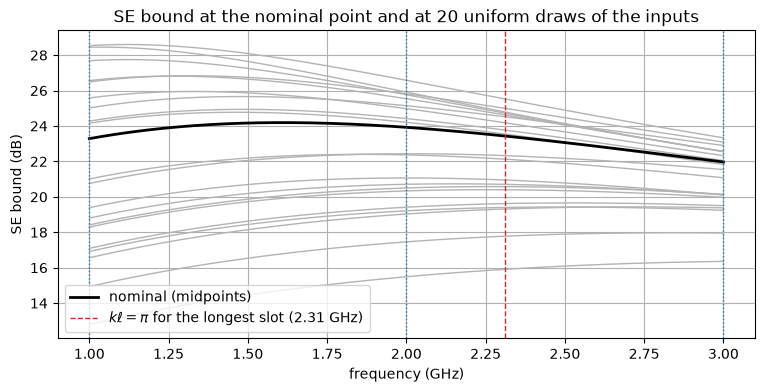

In [3]:
rng = np.random.default_rng(SEED)
Xs = cm.LOWER + (cm.UPPER - cm.LOWER) * rng.random((20, 6))
fgrid = np.linspace(1.0, 3.0, 201)
fig, ax = plt.subplots(figsize=(9, 4))
for x in Xs:
    ax.plot(fgrid, [cm.se_db(x, fg * 1e9)[0] for fg in fgrid], color='0.7', lw=1)
ax.plot(fgrid, [cm.se_db(cm.NOMINAL, fg * 1e9)[0] for fg in fgrid], 'k', lw=2, label='nominal (midpoints)')
xl = cm.NOMINAL.copy(); xl[1], xl[4] = 2.5, 3.6
f_res = cm.C0 / (2 * cm.parts(xl, 1e9)['l'][0]) / 1e9
ax.axvline(f_res, color='C3', ls='--', lw=1, label=f'$k\\ell = \\pi$ for the longest slot ({f_res:.2f} GHz)')
for fg in cm.FREQS_GHZ:
    ax.axvline(fg, color='C0', ls=':', lw=1)
ax.set_xlabel('frequency (GHz)')
ax.set_ylabel('SE bound (dB)')
ax.set_title('SE bound at the nominal point and at 20 uniform draws of the inputs')
ax.legend(loc='lower left')
ax.grid(True)
plt.close(fig)
print(f'half-wave slot resonance of the longest slot (l_p = 2.5 in, a = 3.6 in): {f_res:.4f} GHz; '
      f'of the nominal slot: {cm.C0 / (2 * cm.parts(cm.NOMINAL, 1e9)["l"][0]) / 1e9:.4f} GHz')
fig

At the nominal point (all midpoints) the bound is 23.285 dB at 1 GHz, 24.166 dB at 1.5 GHz, 23.925 dB at 2 GHz and 21.967 dB at 3 GHz; the slot's internal loss term $R_{\mathrm{int}}\pi^2/(\omega L\ell)^2$ dominates the radiation conductance $G_{\mathrm{rad}}$ at low frequency (0.0647 against 0.0051 at 1 GHz) and the order reverses by 3 GHz (0.0125 against 0.0422). The curves are smooth in frequency: the matched model has no cavity resonances (the TM$_{010}$ resonance near 1.129 GHz of the paper's Fig. 1(b) belongs to its unmatched model, Appendix B, which is not built here). The half-wave slot resonance $k\ell = \pi$ is at 2.3114 GHz for the longest slot of the design space and at 2.9194 GHz for the nominal slot; the formula for $G_{\mathrm{rad}}$ is smooth through it, and so are SE and its gradient (`check_accuracy.py`, check 4: the second difference in frequency at $k\ell = \pi$ equals the median one to 1.00). Above it the model is used outside the range the paper states for it, as the paper's own 1–3 GHz study does.

### Load data

`generate_data.py` drew $M = 1000$ independent Monte Carlo samples of the six inputs, uniform on the Table 1 ranges (seed 2021), and wrote the physical inputs, the four outputs, and their complex-step gradients with respect to the physical inputs in the paper's units (dB/in, dB/in, dB/mil, dB/in, dB/in, dB per $10^7$ S/m). The script takes a few seconds (see `DATA.md`).

In [4]:
X = np.loadtxt('inputs.csv', delimiter=',')                       # (M, 6) d, l_p, w, h, a, sigma (paper units)
f = np.loadtxt('outputs.csv', delimiter=',')                      # (M, 4) SE at 1, 2, 3 GHz and band mean (dB)
G = np.loadtxt('gradients.csv', delimiter=',').reshape(-1, 4, 6)  # (M, 4, 6) dSE/dx, physical units
print(f'inputs {X.shape}, outputs {f.shape}, gradients {G.shape}')

inputs (1000, 6), outputs (1000, 4), gradients (1000, 4, 6)


We check the files against the model at five samples and the gradients there against central differences, and count the samples that lie above the slot resonance ($k\ell > \pi$) at each frequency.

In [5]:
rows = [0, 1, 2, 3, 4]
fm, Gm = cm.qois(X[rows], grad=True)
h = 1e-6 * (cm.UPPER - cm.LOWER)
Gfd = np.stack([(cm.qois(X[rows] + h[j] * e) - cm.qois(X[rows] - h[j] * e)) / (2 * h[j])
                for j, e in enumerate(np.eye(6))], axis=-1)
print(f'model vs outputs.csv at rows {rows}: max abs difference {np.max(np.abs(fm - f[rows])):.1e} dB; '
      f'gradients: max relative difference {np.max(np.abs(Gm - G[rows])) / np.max(np.abs(G[rows])):.1e}')
print(f'gradients vs central differences (step 1e-6 of each range): max relative error (row 2-norm) '
      f'{np.max(np.linalg.norm(Gfd - G[rows], axis=2) / np.linalg.norm(G[rows], axis=2)):.1e}')
for q in range(4):
    print(f'{cm.QOI_NAMES[q]:8s} range [{f[:, q].min():.2f}, {f[:, q].max():.2f}] dB, mean {f[:, q].mean():.2f}, sd {f[:, q].std(ddof=1):.2f}')
for fg in cm.FREQS_GHZ:
    r = cm.kl_over_pi(X, fg * 1e9)
    print(f'{fg:.0f} GHz: k l / pi in [{r.min():.3f}, {r.max():.3f}]; samples above the slot resonance (k l > pi): {(r > 1).sum()}')
r = np.array([cm.kl_over_pi(X, fg * 1e9) for fg in cm.BAND_GHZ])
print(f'band: samples with k l > pi at one or more of the 51 frequencies: {(r > 1).any(axis=0).sum()}')

model vs outputs.csv at rows [0, 1, 2, 3, 4]: max abs difference 0.0e+00 dB; gradients: max relative difference 0.0e+00
gradients vs central differences (step 1e-6 of each range): max relative error (row 2-norm) 8.3e-09
SE_1GHz  range [10.26, 29.92] dB, mean 22.23, sd 4.05
SE_2GHz  range [13.09, 27.27] dB, mean 22.90, sd 2.76
SE_3GHz  range [14.28, 23.88] dB, mean 21.31, sd 1.61
SE_band  range [12.81, 27.20] dB, mean 22.52, sd 2.78
1 GHz: k l / pi in [0.256, 0.431]; samples above the slot resonance (k l > pi): 0
2 GHz: k l / pi in [0.511, 0.862]; samples above the slot resonance (k l > pi): 0
3 GHz: k l / pi in [0.767, 1.293]; samples above the slot resonance (k l > pi): 569


band: samples with k l > pi at one or more of the 51 frequencies: 569


The model reproduces the stored outputs and gradients at these rows to the last digit written (differences of order $10^{-16}$ or below; the files hold 17 significant digits). The complex-step gradients agree with central differences (step $10^{-6}$ of each range) to $8.3\times10^{-9}$, the round-off level of the differences; `check_accuracy.py` compares them with Richardson-extrapolated differences of an independent scipy implementation at all 1000 rows, to $4.9\times10^{-11}$. Over the samples the bound spans 13.09–27.27 dB at 2 GHz (mean 22.90, sd 2.76) and 10.26–29.92 dB at 1 GHz. At 1 and 2 GHz every sample is below the slot resonance ($k\ell/\pi \le 0.862$), although at 2 GHz the longest slots, at $k\ell/\pi = 0.862$, are hardly "electrically short" in the sense of p. 20; at 3 GHz 569 of 1000 are above it ($k\ell/\pi$ up to 1.293), and the same 569 are above it at one or more of the 51 band frequencies. They are kept, as in the paper's study, and only the 1 and 2 GHz outputs are entirely within the model's stated range.

### Estimate the subspace

The model is closed-form and smooth and we have gradients accurate to rounding, so we use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates. The input space is `ac.Uniform` on the Table 1 bounds; we pass the physical inputs and gradients, and the library scales each input to $[-1, 1]$ (the normalized gradient is $\tfrac12(u_i - l_i)\,\partial f/\partial x_i$). We use 500 bootstrap replicates and orient each eigenvector so that the output increases along it (`by="covariance"`); the paper has no eigenvectors to match. We print the eigenvalues, the ratios of successive eigenvalues, the share of the trace outside $\lambda_1$ and outside $\lambda_1, \lambda_2$, and, for reference, what the library's eigenvalue-gap rule gives with its default linear gap ($\lambda_k - \lambda_{k+1}$) and with the log gap (the ratio). We choose the dimension for each output from the ratios, their bootstrap intervals, the share of the trace left out and the surrogates below, not from either rule.

In [6]:
space = ac.Uniform(cm.LOWER, cm.UPPER, names=list(cm.NAMES))
subs = []
for q in range(4):
    sub = ac.active_subspace(space=space, X=X, f=f[:, q], grads=G[:, q], estimator='as', nboot=500, rng=SEED)
    sub = ac.orient(sub, by='covariance', X=X, f=f[:, q], columns=6)
    subs.append(sub)
    lam = sub.eigenvalues
    k_lin = ac.dimension_criterion(sub, rule=ac.subspaces.EVG(gap='linear'))[2]
    k_log = ac.dimension_criterion(sub, rule=ac.subspaces.EVG(gap='log'))[2]
    print(f'{cm.QOI_NAMES[q]:8s} eigenvalues {np.array2string(lam, precision=4)}')
    print(f'         ratios lambda_k/lambda_(k+1) {np.array2string(lam[:-1] / lam[1:], formatter={"float_kind": lambda v: f"{v:.1f}"})}; '
          f'largest ratio after lambda_{int(np.argmax(lam[:-1] / lam[1:])) + 1}')
    print(f'         share of trace outside lambda_1 {lam[1:].sum() / lam.sum():.4f}, outside lambda_1, lambda_2 {lam[2:].sum() / lam.sum():.5f}; '
          f'library gap rule: linear gap n = {k_lin}, log gap n = {k_log}')

SE_1GHz  eigenvalues [6.7243e+01 1.9519e+00 3.5487e-02 6.1065e-03 2.2608e-03 3.7545e-04]
         ratios lambda_k/lambda_(k+1) [34.4 55.0 5.8 2.7 6.0]; largest ratio after lambda_2
         share of trace outside lambda_1 0.0288, outside lambda_1, lambda_2 0.00064; library gap rule: linear gap n = 1, log gap n = 2


SE_2GHz  eigenvalues [4.0344e+01 9.3553e-01 5.9010e-02 4.1396e-03 1.9476e-03 3.7340e-04]
         ratios lambda_k/lambda_(k+1) [43.1 15.9 14.3 2.1 5.2]; largest ratio after lambda_1
         share of trace outside lambda_1 0.0242, outside lambda_1, lambda_2 0.00158; library gap rule: linear gap n = 1, log gap n = 1


SE_3GHz  eigenvalues [1.8526e+01 5.0592e-01 5.0169e-02 1.7596e-03 1.2515e-03 3.5258e-04]
         ratios lambda_k/lambda_(k+1) [36.6 10.1 28.5 1.4 3.5]; largest ratio after lambda_1
         share of trace outside lambda_1 0.0293, outside lambda_1, lambda_2 0.00280; library gap rule: linear gap n = 1, log gap n = 1


SE_band  eigenvalues [3.9451e+01 9.8071e-01 4.7923e-02 3.7783e-03 1.9574e-03 3.7157e-04]
         ratios lambda_k/lambda_(k+1) [40.2 20.5 12.7 1.9 5.3]; largest ratio after lambda_1
         share of trace outside lambda_1 0.0256, outside lambda_1, lambda_2 0.00133; library gap rule: linear gap n = 1, log gap n = 1


### Results

**Eigenvalues and subspace errors** at 2 GHz, with 95 % bootstrap bands; the printed lines give the bootstrap spread for all four outputs.

SE_1GHz  lambda_1/lambda_2 over the bootstrap replicates: 2.5-97.5 % [32.2, 37.2]; lambda_2/lambda_3 [49.8, 60.5]; lambda_3/lambda_4 [5.2, 6.5]; mean subspace distance k=1: 0.005, k=2: 0.004, k=3: 0.015
SE_2GHz  lambda_1/lambda_2 over the bootstrap replicates: 2.5-97.5 % [39.9, 47.5]; lambda_2/lambda_3 [14.4, 17.3]; lambda_3/lambda_4 [12.9, 15.9]; mean subspace distance k=1: 0.005, k=2: 0.007, k=3: 0.010
SE_3GHz  lambda_1/lambda_2 over the bootstrap replicates: 2.5-97.5 % [33.1, 41.2]; lambda_2/lambda_3 [9.3, 11.1]; lambda_3/lambda_4 [24.8, 32.3]; mean subspace distance k=1: 0.006, k=2: 0.010, k=3: 0.009
SE_band  lambda_1/lambda_2 over the bootstrap replicates: 2.5-97.5 % [37.4, 44.2]; lambda_2/lambda_3 [18.7, 22.4]; lambda_3/lambda_4 [11.4, 14.0]; mean subspace distance k=1: 0.005, k=2: 0.006, k=3: 0.011


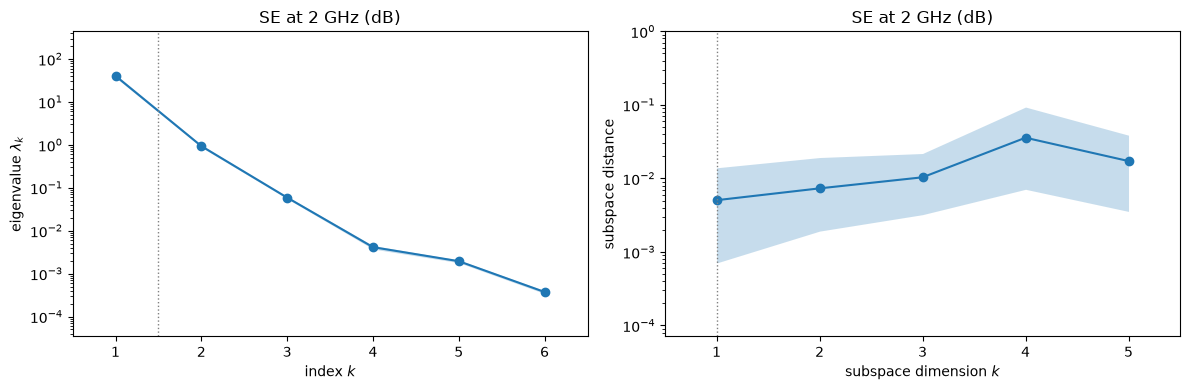

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ac.plotting.plot_eigenvalues(subs[1], ax=axes[0])
axes[0].set_title(qlabels[1])
ac.plotting.plot_subspace_errors(subs[1], ax=axes[1])
axes[1].set_title(qlabels[1])
fig.tight_layout()
plt.close(fig)
for q in range(4):
    b = subs[q].bootstrap_eigenvalues
    dist = subs[q].bootstrap_distances.mean(axis=0)
    print(f'{cm.QOI_NAMES[q]:8s} lambda_1/lambda_2 over the bootstrap replicates: 2.5-97.5 % '
          f'[{np.percentile(b[:, 0] / b[:, 1], 2.5):.1f}, {np.percentile(b[:, 0] / b[:, 1], 97.5):.1f}]; '
          f'lambda_2/lambda_3 [{np.percentile(b[:, 1] / b[:, 2], 2.5):.1f}, {np.percentile(b[:, 1] / b[:, 2], 97.5):.1f}]; '
          f'lambda_3/lambda_4 [{np.percentile(b[:, 2] / b[:, 3], 2.5):.1f}, {np.percentile(b[:, 2] / b[:, 3], 97.5):.1f}]; '
          'mean subspace distance ' + ', '.join(f'k={k + 1}: {d:.3f}' for k, d in enumerate(dist[:3])))
fig

At 2 GHz $\lambda_1 = 40.344$ and $\lambda_2 = 0.93553$, so $\lambda_1/\lambda_2 = 43.1$ (39.9–47.5 over the bootstrap replicates), and the five eigenvalues after the first hold 0.0242 of the trace. The next ratio, $\lambda_2/\lambda_3 = 15.9$ (14.4–17.3), is a second, clearly smaller gap; the two intervals do not overlap. **At 2 GHz we use $n = 1$**: the first gap is the largest and is well separated over the bootstrap, and a quadratic in $y_1$ already has leave-one-out $R^2 = 0.96392$. Two active variables are also defensible there: the surrogates below gain from $y_2$ ($R^2$ 0.99134 for a quadratic in $(y_1, y_2)$), and only 0.00158 of the trace lies outside $\lambda_1, \lambda_2$. The bootstrap mean subspace distance is 0.005 for $n = 1$ and 0.007 for $n = 2$, so both are well determined by 1000 samples.

The order of the gaps differs between the outputs, so we choose $n$ for each:

- **1 GHz.** $\lambda_1/\lambda_2 = 34.4$ (32.2–37.2) but $\lambda_2/\lambda_3 = 55.0$ (49.8–60.5): the larger gap is after $\lambda_2$, and the intervals do not overlap. Only 0.00064 of the trace lies outside $\lambda_1, \lambda_2$, against 0.0288 outside $\lambda_1$, and the quadratic leave-one-out $R^2$ rises from 0.97384 in $y_1$ to 0.99710 in $(y_1, y_2)$. **At 1 GHz we choose $n = 2$.** The first direction alone still carries most of the variation (cubic in $y_1$: 0.97588), and the subspace distances are small for both choices (0.005 for $n = 1$, 0.004 for $n = 2$), so the one-dimensional summary remains useful there.
- **3 GHz.** $\lambda_1/\lambda_2 = 36.6$ (33.1–41.2) is the largest ratio; the next are $\lambda_2/\lambda_3 = 10.1$ (9.3–11.1) and $\lambda_3/\lambda_4 = 28.5$ (24.8–32.3), so there is also a clear gap after $\lambda_3$, comparable to the first. We use $n = 1$ (0.0293 of the trace outside $\lambda_1$), with the weakest one-variable surrogate of the four (cubic 0.94640; quadratic in $(y_1, y_2)$ 0.97567), as expected where 569 samples are above the slot resonance.
- **Band mean.** $\lambda_1/\lambda_2 = 40.2$ (37.4–44.2) against $\lambda_2/\lambda_3 = 20.5$ (18.7–22.4), and 0.0256 of the trace outside $\lambda_1$: $n = 1$, as at 2 GHz.

For reference, the library's eigenvalue-gap rule gives $n = 1$ for all four outputs with its default linear gap, which favours $n = 1$ whenever $\lambda_1$ dominates the trace, and $n = 2, 1, 1, 1$ with the log gap; the choices above agree with the log gap, but they rest on the ratios, intervals and surrogates, not on the rule.

SE_1GHz  w1 = [-0.0918  0.3584  0.9234 -0.0416 -0.0585  0.0727]
SE_2GHz  w1 = [-0.0789  0.3206  0.9375 -0.0479 -0.0663  0.0737]
SE_3GHz  w1 = [-0.0696  0.3046  0.9404 -0.0621 -0.0851  0.0834]
SE_band  w1 = [-0.0804  0.3269  0.9348 -0.0495 -0.0686  0.0757]
SE_2GHz  w2 = [-0.175   0.8276 -0.3452 -0.1949 -0.2636  0.2406]
|w1(SE_1GHz) . w1(SE_2GHz)| = 0.99905
|w1(SE_3GHz) . w1(SE_2GHz)| = 0.99950
|w1(SE_band) . w1(SE_2GHz)| = 0.99997


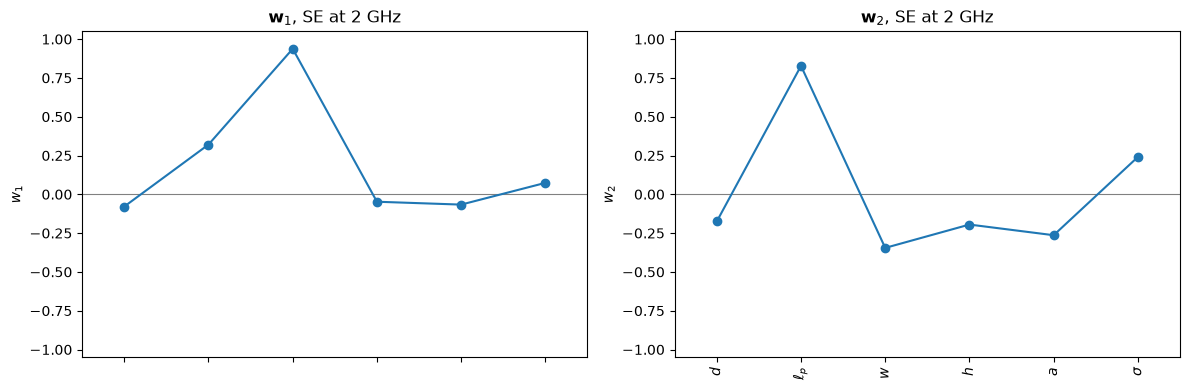

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ac.plotting.plot_eigenvectors(subs[1], indices=[0, 1], labels=labels, ax=axes)
axes[0].set_title(r'$\mathbf{w}_1$, SE at 2 GHz')
axes[1].set_title(r'$\mathbf{w}_2$, SE at 2 GHz')
fig.tight_layout()
plt.close(fig)
for q in range(4):
    print(f'{cm.QOI_NAMES[q]:8s} w1 = {np.array2string(subs[q].W[:, 0], precision=4)}')
print(f'SE_2GHz  w2 = {np.array2string(subs[1].W[:, 1], precision=4)}')
for q in (0, 2, 3):
    print(f'|w1({cm.QOI_NAMES[q]}) . w1(SE_2GHz)| = {abs(subs[q].W[:, 0] @ subs[1].W[:, 0]):.5f}')
fig

At 2 GHz the SE bound increases along $\mathbf w_1 = (-0.0789, 0.3206, 0.9375, -0.0479, -0.0663, 0.0737)$ in the order $d, \ell_p, w, h, a, \sigma$: a wider and longer slot lets in more power, and a deeper slot less; a larger cavity (more wall area) and a lower conductivity absorb more, lowering the bound, but these three cavity entries are small. The slot width dominates ($w_{1,3}^2 = 0.879$). The direction barely moves with frequency: $|\mathbf w_1\cdot\mathbf w_1^{(2\,\mathrm{GHz})}| = 0.99905$ at 1 GHz, 0.99950 at 3 GHz and 0.99997 for the band mean, so the 2 GHz subspace serves the whole band. The second eigenvector, $\mathbf w_2 = (-0.175, 0.8276, -0.3452, -0.1949, -0.2636, 0.2406)$, is mostly the slot length.

SE_1GHz  y1 in [-1.33, 1.29]; corr(y1, f) = 0.97279
SE_2GHz  y1 in [-1.32, 1.28]; corr(y1, f) = 0.93245
SE_3GHz  y1 in [-1.33, 1.31]; corr(y1, f) = 0.87204
SE_band  y1 in [-1.32, 1.29]; corr(y1, f) = 0.94141


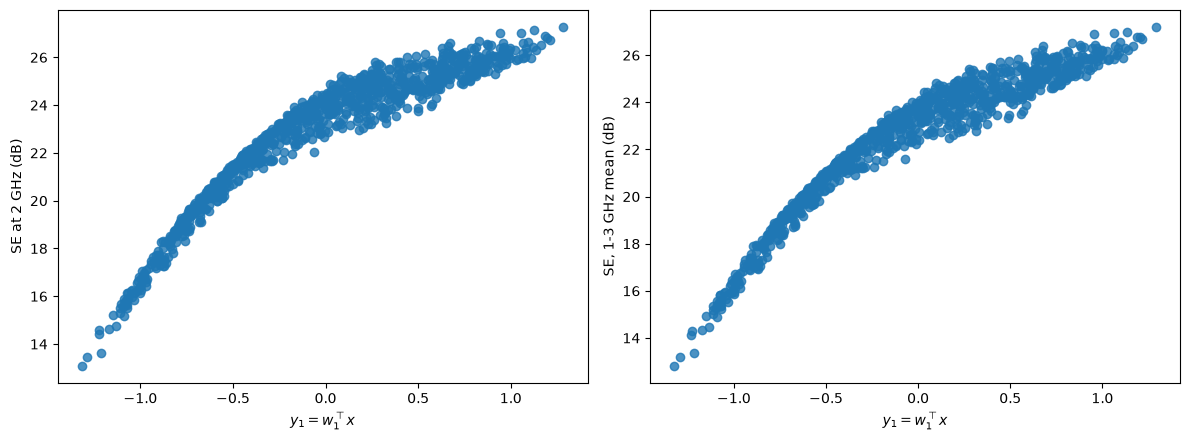

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(subs[1], X=X, f=f[:, 1], dims=1, qoi_label=qlabels[1], ax=axes[0])
ac.plotting.plot_sufficient_summary(subs[3], X=X, f=f[:, 3], dims=1, qoi_label=qlabels[3], ax=axes[1])
fig.tight_layout()
plt.close(fig)
XN = space.to_normalized(X)
for q in range(4):
    y = XN @ subs[q].W[:, 0]
    print(f'{cm.QOI_NAMES[q]:8s} y1 in [{y.min():.2f}, {y.max():.2f}]; corr(y1, f) = {np.corrcoef(y, f[:, q])[0, 1]:.5f}')
fig

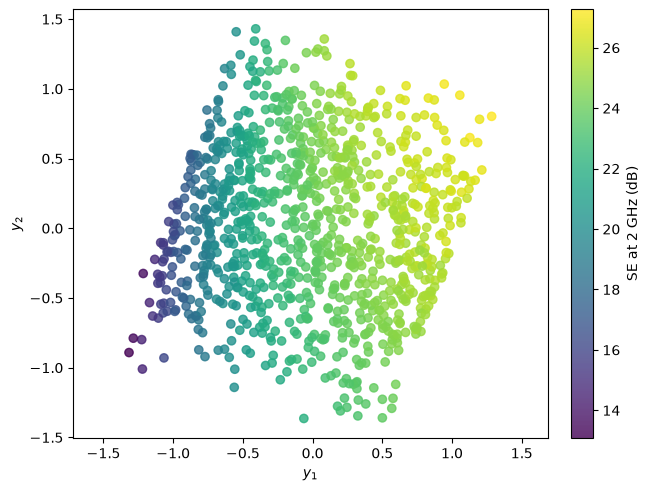

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(ac.with_dimension(subs[1], 2), X=X, f=f[:, 1], dims=2, qoi_label=qlabels[1])
plt.close(fig)
fig

The one-dimensional summary plots show a concave trend (the bound rises steeply with $y_1$ for narrow, short slots and flattens for wide ones) with $\mathrm{corr}(y_1, f) = 0.93245$ at 2 GHz and 0.94141 for the band mean; $y_1$ spans $[-1.32, 1.28]$. The scatter about the trend grows with $y_1$. In the two-dimensional plot at 2 GHz the colour changes mainly along $y_1$ and somewhat along $y_2$ (the slot length), which is that scatter.

#### Surrogates on the active variables

We fit polynomials in the first active variable (degrees 2 and 3) and, for comparison, a quadratic in the first two, and report the leave-one-out $R^2$; the figure shows the cubic in $y_1$ at 2 GHz.

SE_1GHz  quadratic, n = 1  LOO R^2 = 0.97384
SE_1GHz  cubic, n = 1      LOO R^2 = 0.97588
SE_1GHz  quadratic, n = 2  LOO R^2 = 0.99710
SE_2GHz  quadratic, n = 1  LOO R^2 = 0.96392
SE_2GHz  cubic, n = 1      LOO R^2 = 0.97182
SE_2GHz  quadratic, n = 2  LOO R^2 = 0.99134
SE_3GHz  quadratic, n = 1  LOO R^2 = 0.91745
SE_3GHz  cubic, n = 1      LOO R^2 = 0.94640
SE_3GHz  quadratic, n = 2  LOO R^2 = 0.97567
SE_band  quadratic, n = 1  LOO R^2 = 0.96411
SE_band  cubic, n = 1      LOO R^2 = 0.97148
SE_band  quadratic, n = 2  LOO R^2 = 0.99240


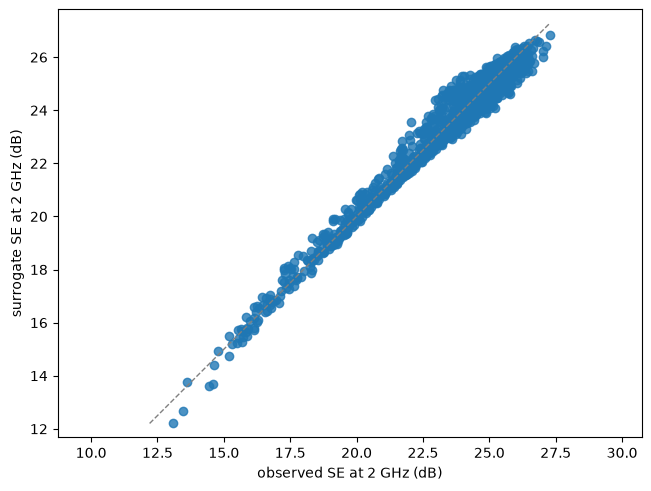

In [11]:
surs = {}
for q in range(4):
    for name, sub_k, deg in [('quadratic, n = 1', subs[q], 2), ('cubic, n = 1', subs[q], 3),
                             ('quadratic, n = 2', ac.with_dimension(subs[q], 2), 2)]:
        s = ac.fit_surrogate(X=X, f=f[:, q], subspace=sub_k, kind='poly', degree=deg)
        surs[q, name] = s
        print(f'{cm.QOI_NAMES[q]:8s} {name:17s} LOO R^2 = {s.loo_r_squared:.5f}')
fig, ax = ac.plotting.plot_surrogate_fit(surs[1, 'cubic, n = 1'], X=X, f=f[:, 1], qoi_label=qlabels[1])
plt.close(fig)
fig

At 2 GHz a cubic in $y_1$ has leave-one-out $R^2 = 0.97182$ (quadratic 0.96392), and a quadratic in $(y_1, y_2)$ 0.99134. The band mean behaves like 2 GHz (0.97148 and 0.99240); 1 GHz is a little better (0.97588, 0.99710) and 3 GHz, where most samples are above the slot resonance, worse (0.94640, 0.97567). One active variable gives a useful surrogate at every frequency; the second adds 2–3 points of $R^2$, most relative to what is left at 1 GHz, where we take $n = 2$.

#### Normal inputs (Table 3)

Table 3 (p. 35) also gives normal distributions with the Table 1 midpoints as means and standard deviations of one sixth of each range; the paper applies them to its unmatched model in Sec. 4. Applying them to the matched bound is our choice, to see whether the subspace depends on the input distribution. We draw 1000 normal samples with the notebook's seed, compute the 2 GHz output and its gradient with the model, and use `ac.Gaussian` (each input scaled by its standard deviation). Normal draws can leave the Table 1 box; we count them and keep them, since every one is physically meaningful (positive width, slot shorter than the diameter).

In [12]:
gspace = ac.Gaussian(cm.NOMINAL, np.diag(cm.NORMAL_SD ** 2), names=list(cm.NAMES))
Xg = cm.NOMINAL + cm.NORMAL_SD * np.random.default_rng(SEED).standard_normal((1000, 6))
print(f'normal draws: min w = {Xg[:, 2].min():.2f} mil, max l_p / (2a) = {(Xg[:, 1] / (2 * Xg[:, 4])).max():.3f}; '
      f'samples outside the Table 1 box: {int(np.any((Xg < cm.LOWER) | (Xg > cm.UPPER), axis=1).sum())}')
fg_, Gg = cm.se_db(Xg, 2e9, grad=True)
subg = ac.active_subspace(space=gspace, X=Xg, f=fg_, grads=Gg, estimator='as', nboot=500, rng=SEED)
subg = ac.orient(subg, by='covariance', X=Xg, f=fg_, columns=6)
lam = subg.eigenvalues
b = subg.bootstrap_eigenvalues
print(f'SE_2GHz, normal inputs: mean {fg_.mean():.2f} dB, sd {fg_.std(ddof=1):.2f} dB')
print(f'eigenvalues {np.array2string(lam, precision=4)}; lambda_1/lambda_2 = {lam[0] / lam[1]:.1f} '
      f'(bootstrap 2.5-97.5 %: [{np.percentile(b[:, 0] / b[:, 1], 2.5):.1f}, {np.percentile(b[:, 0] / b[:, 1], 97.5):.1f}])')
print(f'w1 = {np.array2string(subg.W[:, 0], precision=4)}; |w1 . w1(uniform)| = {abs(subg.W[:, 0] @ subs[1].W[:, 0]):.4f}')
print(f'quadratic in y1, LOO R^2 = {ac.fit_surrogate(X=Xg, f=fg_, subspace=subg, kind="poly", degree=2).loo_r_squared:.5f}')

normal draws: min w = 4.51 mil, max l_p / (2a) = 0.329; samples outside the Table 1 box: 12


SE_2GHz, normal inputs: mean 23.61 dB, sd 1.37 dB
eigenvalues [2.2279e+00 4.2567e-02 2.4133e-03 1.2313e-04 7.0002e-05 1.3466e-05]; lambda_1/lambda_2 = 52.3 (bootstrap 2.5-97.5 %: [44.0, 65.3])
w1 = [-0.1068  0.425   0.8825 -0.0766 -0.1055  0.11  ]; |w1 . w1(uniform)| = 0.9908
quadratic in y1, LOO R^2 = 0.97630


With normal inputs 12 of the 1000 draws are outside the Table 1 box (the smallest width is 4.51 mil), all within the model's domain. The SE bound at 2 GHz has mean 23.61 dB and sd 1.37 dB, half the uniform spread (2.76 dB), because the normal inputs are concentrated near the midpoints. The active subspace is again one-dimensional, $\lambda_1/\lambda_2 = 52.3$ (bootstrap 44.0–65.3), with $\mathbf w_1 = (-0.1068, 0.425, 0.8825, -0.0766, -0.1055, 0.11)$, which is $|\mathbf w_1\cdot\mathbf w_1^{\mathrm{unif}}| = 0.9908$ from the uniform direction; the entries differ because the model is curved in $w$: the normal draws stay near the midpoint, where SE is less steep in $w$ than for the narrow slots the uniform design reaches, so $\ell_p$ gains weight. A quadratic in $y_1$ has leave-one-out $R^2 = 0.97630$.

### Comparison with the paper

The paper [[1]][R1] does not compute an active subspace. For the matched bound it reports first-order and total Sobol indices at 51 frequencies from fourth-order polynomial chaos fitted to 448 Latin hypercube runs (Fig. 2, p. 27; pp. 8–9), and one-at-a-time sweeps of each input with the others at their midpoints (Fig. 3, p. 28). Its uncertainty propagation (Sec. 4: Tables 4–5, Figs. 6–7) uses the *unmatched* model of Appendix B and the full-wave code EIGER, for the peak SE of the TM$_{010}$ resonance. Neither is built here, and the unmatched model cannot be rebuilt from the paper: its Eq. (8) (p. 22) needs the slot voltage drive $V(0)$, which is given only as "proportional to the exterior short circuit current density at the center of the slot" $K_z^{sc}$, with no formula or constant; the symbols $b$ and $\varepsilon_m$ in Eq. (8) are not defined (only $\varepsilon_n$ is); and the observation point $\mathbf r$ at which the peak SE is taken is not stated. Table 5 also comes from polynomial chaos surrogates fitted to 112 Latin hypercube runs of that model (p. 13), not from the model itself. Those numbers are therefore not comparable with this data set.

We estimate the Sobol indices of our model directly, with the Jansen estimators listed in Saltelli et al. [[4]][R4] (Table 2 there) on $N = 2^{15}$ uniform Monte Carlo base samples ($8N$ runs per frequency, seed 2021) and 95 % bootstrap intervals (200 resamples), and compare them with the normalized activity scores $\alpha_i/\sum_j\alpha_j$, $\alpha_i = \sum_k\lambda_k w_{ik}^2$ [[3]][R3]. We then repeat the paper's Fig. 3 sweeps (101 points per input).

In [13]:
t0 = time.perf_counter()
N = 2 ** 15
rs = np.random.default_rng(SEED)
A = cm.LOWER + (cm.UPPER - cm.LOWER) * rs.random((N, 6))
B = cm.LOWER + (cm.UPPER - cm.LOWER) * rs.random((N, 6))
boot = rs.integers(0, N, size=(200, N))
sob = {}
for q, fg in enumerate(cm.FREQS_GHZ):
    fA, fB = cm.se_db(A, fg * 1e9), cm.se_db(B, fg * 1e9)
    fAB = []
    for j in range(6):
        ABj = A.copy()
        ABj[:, j] = B[:, j]
        fAB.append(cm.se_db(ABj, fg * 1e9))
    fAB = np.array(fAB)

    def est(idx):
        a, b_, ab = fA[idx], fB[idx], fAB[:, idx]
        V = np.var(np.concatenate([a, b_]))
        return 1 - 0.5 * np.mean((b_ - ab) ** 2, axis=1) / V, 0.5 * np.mean((a - ab) ** 2, axis=1) / V   # Jansen
    S, T = est(np.arange(N))
    Sb, Tb = zip(*[est(i) for i in boot])
    sob[q] = (S, T, np.percentile(Sb, [2.5, 97.5], axis=0), np.percentile(Tb, [2.5, 97.5], axis=0))
    alpha = ac.activity_scores(subs[q], n=6)
    print(f'{fg:.0f} GHz (N = {N}, {N * 8} runs):')
    for j, n in enumerate(cm.NAMES):
        print(f'   {n:6s} S = {S[j]:6.3f} [{sob[q][2][0, j]:6.3f}, {sob[q][2][1, j]:6.3f}]   '
              f'T = {T[j]:6.3f} [{sob[q][3][0, j]:6.3f}, {sob[q][3][1, j]:6.3f}]   '
              f'activity score share {alpha[j] / alpha.sum():.3f}   w1^2 = {subs[q].W[j, 0] ** 2:.3f}')
    print(f'   sum S = {S.sum():.3f}, sum T = {T.sum():.3f}; largest T - S = {np.max(T - S):.3f} ({cm.NAMES[int(np.argmax(T - S))]})')
print(f'{time.perf_counter() - t0:.0f} s')

1 GHz (N = 32768, 262144 runs):
   d      S =  0.018 [ 0.009,  0.029]   T =  0.013 [ 0.013,  0.014]   activity score share 0.010   w1^2 = 0.008
   l_p    S =  0.197 [ 0.187,  0.208]   T =  0.202 [ 0.199,  0.206]   activity score share 0.146   w1^2 = 0.128
   w      S =  0.768 [ 0.764,  0.772]   T =  0.774 [ 0.764,  0.784]   activity score share 0.832   w1^2 = 0.853
   h      S =  0.007 [-0.002,  0.019]   T =  0.003 [ 0.003,  0.003]   activity score share 0.002   w1^2 = 0.002
   a      S =  0.011 [ 0.002,  0.023]   T =  0.006 [ 0.006,  0.006]   activity score share 0.004   w1^2 = 0.003
   sigma  S =  0.011 [ 0.002,  0.024]   T =  0.009 [ 0.008,  0.009]   activity score share 0.006   w1^2 = 0.005
   sum S = 1.012, sum T = 1.006; largest T - S = 0.006 (w)


2 GHz (N = 32768, 262144 runs):
   d      S =  0.014 [ 0.005,  0.026]   T =  0.012 [ 0.012,  0.013]   activity score share 0.007   w1^2 = 0.006
   l_p    S =  0.175 [ 0.165,  0.187]   T =  0.197 [ 0.194,  0.201]   activity score share 0.116   w1^2 = 0.103
   w      S =  0.762 [ 0.758,  0.766]   T =  0.786 [ 0.775,  0.797]   activity score share 0.860   w1^2 = 0.879
   h      S =  0.010 [ 0.000,  0.022]   T =  0.006 [ 0.006,  0.006]   activity score share 0.003   w1^2 = 0.002
   a      S =  0.017 [ 0.007,  0.029]   T =  0.012 [ 0.012,  0.012]   activity score share 0.006   w1^2 = 0.004
   sigma  S =  0.013 [ 0.004,  0.026]   T =  0.013 [ 0.012,  0.013]   activity score share 0.007   w1^2 = 0.005
   sum S = 0.992, sum T = 1.027; largest T - S = 0.024 (w)


3 GHz (N = 32768, 262144 runs):
   d      S =  0.009 [-0.000,  0.021]   T =  0.013 [ 0.012,  0.013]   activity score share 0.005   w1^2 = 0.005
   l_p    S =  0.175 [ 0.163,  0.189]   T =  0.227 [ 0.223,  0.232]   activity score share 0.103   w1^2 = 0.093
   w      S =  0.687 [ 0.680,  0.693]   T =  0.740 [ 0.728,  0.752]   activity score share 0.861   w1^2 = 0.884
   h      S =  0.020 [ 0.009,  0.031]   T =  0.019 [ 0.018,  0.019]   activity score share 0.007   w1^2 = 0.004
   a      S =  0.037 [ 0.027,  0.048]   T =  0.034 [ 0.034,  0.035]   activity score share 0.014   w1^2 = 0.007
   sigma  S =  0.022 [ 0.012,  0.034]   T =  0.026 [ 0.025,  0.026]   activity score share 0.010   w1^2 = 0.007
   sum S = 0.950, sum T = 1.059; largest T - S = 0.053 (w)
8 s


In [14]:
# one-at-a-time sweeps as in the paper's Fig. 3: each input on 101 uniform points, others at the midpoints
for fg in (1.0, 3.0):
    print(f'{fg:.0f} GHz: nominal SE = {cm.se_db(cm.NOMINAL, fg * 1e9)[0]:.2f} dB')
    for j, n in enumerate(cm.NAMES):
        Xo = np.tile(cm.NOMINAL, (101, 1))
        Xo[:, j] = np.linspace(cm.LOWER[j], cm.UPPER[j], 101)
        s = cm.se_db(Xo, fg * 1e9)
        print(f'   {n:6s} min {s.min():6.2f}  mean {s.mean():6.2f}  max {s.max():6.2f} dB')

1 GHz: nominal SE = 23.28 dB
   d      min  22.55  mean  23.31  max  24.18 dB
   l_p    min  19.66  mean  23.13  max  25.97 dB
   w      min  14.03  mean  22.47  max  27.19 dB
   h      min  22.93  mean  23.29  max  23.67 dB
   a      min  22.79  mean  23.29  max  23.84 dB
   sigma  min  22.58  mean  23.27  max  23.88 dB
3 GHz: nominal SE = 21.97 dB
   d      min  21.77  mean  21.97  max  22.17 dB
   l_p    min  20.66  mean  21.87  max  22.68 dB
   w      min  17.46  mean  21.44  max  22.65 dB
   h      min  21.61  mean  21.97  max  22.36 dB
   a      min  21.48  mean  21.97  max  22.50 dB
   sigma  min  21.52  mean  21.96  max  22.35 dB


The Sobol indices of our implementation agree with the paper's Fig. 2 to within what can be read from the figure (about 0.01), at both ends of the band. The sums of the first-order indices are 1.012, 0.992 and 0.950 at 1, 2 and 3 GHz, and the total indices exceed the first-order ones by at most 0.053 (the slot width at 3 GHz; 0.024 at 2 GHz), so interactions are small and grow with frequency, as the paper notes (p. 9). Some first-order estimates exceed the total-order ones (e.g. $S_d = 0.018 > T_d = 0.013$ at 1 GHz, and the sum 1.012 > 1): this is noise of the Jansen first-order estimator, whose intervals are about $\pm 0.01$ wide, not a property of the model. The paper also says that below 1.5 GHz "slot depth contributed slightly more than the other three parameters" (p. 9); here $T_d = 0.013$ against $T_\sigma = 0.009$, $T_a = 0.006$ and $T_h = 0.003$ at 1 GHz, and at 3 GHz $T_d = 0.013$ falls below $T_a = 0.034$, $T_\sigma = 0.026$ and $T_h = 0.019$. The activity scores rank the inputs the same way but give the slot width a larger share (0.832–0.861 against first-order indices of 0.687–0.768), because they weight the squared derivative, which is largest for narrow slots where SE is steep in $w$, rather than the variance of the conditional mean. The one-at-a-time sweeps match the paper's Fig. 3 within the precision of reading its axes.

| Quantity | Paper value | Notebook value |
|---|---|---|
| Model | matched power-balance bound, Appendix A, Eqs. (5)–(6), pp. 20–21 | same equations (numpy), slot arc length from $\ell_p$ (p. 4) |
| Design | 448 Latin hypercube runs, 51 frequencies 1–3 GHz (p. 8) | 1000 uniform Monte Carlo samples; outputs at 1, 2, 3 GHz and the 51-frequency mean |
| Nominal SE at 1 GHz; 3 GHz | about 23; about 22 dB (Fig. 3, yellow mean curves, read by eye) | 23.28; 21.97 dB |
| $w$ sweep, min–max at 1 GHz; 3 GHz | about 14.5–27.3; 17.5–22.7 dB (Fig. 3) | 14.03–27.19; 17.46–22.65 dB |
| $\ell_p$ sweep, min–max at 1 GHz; 3 GHz | about 20–26; 21–23 dB (Fig. 3) | 19.66–25.97; 20.66–22.68 dB |
| $d$, $h$, $a$, $\sigma$ sweeps | each within about 2 dB (Fig. 3) | widest: $d$ at 1 GHz, 22.55–24.18 dB |
| $S_w$, $T_w$ at 1 GHz | about 0.77, 0.77 (Fig. 2, read by eye) | 0.768 [0.764, 0.772], 0.774 [0.764, 0.784] |
| $S_w$, $T_w$ at 3 GHz | about 0.69, 0.73 (Fig. 2) | 0.687 [0.680, 0.693], 0.740 [0.728, 0.752] |
| $S_\ell$, $T_\ell$ at 1 GHz | about 0.20, 0.20 (Fig. 2) | 0.197 [0.187, 0.208], 0.202 [0.199, 0.206] |
| $S_\ell$, $T_\ell$ at 3 GHz | about 0.18, 0.22 (Fig. 2) | 0.175 [0.163, 0.189], 0.227 [0.223, 0.232] |
| $d$, $h$, $a$, $\sigma$ indices | "negligible", below about 0.04 (Fig. 2; p. 9) | each at most 0.037 ($S_a$ at 3 GHz) |
| Slot width share of variance | "70%–80%" (p. 9) | $S_w$ 0.768, 0.762, 0.687 at 1, 2, 3 GHz |
| PCE cross-validation MSE | $3\times10^{-4}$ to $7\times10^{-4}$ (p. 9) | not applicable (the model is evaluated directly) |
| Peak SE of TM$_{010}$ (unmatched model), mean, sd: normal; uniform | 11.3, 3.1; 10.7, 5.5 dB (Table 5, p. 37) | not reproduced: Eq. (8) of Appendix B needs $V(0)$ (given only as proportional to $K_z^{sc}$, p. 22), uses undefined $b$ and $\varepsilon_m$, and the observation point is not stated; Table 5 is from PCE surrogates of 112 LHS runs (p. 13) |
| Active subspace | not reported | $n = 1$ at 2 and 3 GHz and for the band mean ($\lambda_1/\lambda_2 = 43.1$ at 2 GHz); $n = 2$ at 1 GHz ($\lambda_2/\lambda_3 = 55.0 > \lambda_1/\lambda_2 = 34.4$) |
| Normalized activity scores ($d, \ell_p, w, h, a, \sigma$), 2 GHz | not reported | 0.007, 0.116, 0.860, 0.003, 0.006, 0.007 |

The agreement of the sweeps and Sobol indices supports our reading of the printed equations (including $10\log_{10}$ for Eq. (6); $20\log_{10}$ would give 47.85 dB at the nominal point at 2 GHz, off the figure's axes), although the figures cannot separate the two readings of the Table 1 slot lengths (projected or arc length), which differ by less than 0.13 dB at the nominal point.

### References

[1] S. Campione, J. A. Stephens, N. Martin, A. Eckert, L. K. Warne, G. Huerta, R. A. Pfeiffer, and A. Jones. [Developing uncertainty quantification strategies in electromagnetic problems involving highly resonant cavities](https://doi.org/10.1115/1.4051906). *Journal of Verification, Validation and Uncertainty Quantification*, 6(4):041003, 2021. (Read from the accepted manuscript, SAND2021-8020J, page numbers as there.)

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[3] P. G. Constantine and P. Diaz. [Global sensitivity metrics from active subspaces](https://doi.org/10.1016/j.ress.2017.01.013). *Reliability Engineering & System Safety*, 162:1–13, 2017.

[4] A. Saltelli, P. Annoni, I. Azzini, F. Campolongo, M. Ratto, and S. Tarantola. [Variance based sensitivity analysis of model output. Design and estimator for the total sensitivity index](https://doi.org/10.1016/j.cpc.2009.09.018). *Computer Physics Communications*, 181(2):259–270, 2010.

[5] S. Campione, L. K. Warne, W. L. Langston, R. A. Pfeiffer, N. Martin, J. T. Williams, R. K. Gutierrez, I. C. Reines, J. G. Huerta, and V. Q. Dang. [Penetration through slots in cylindrical cavities operating at fundamental cavity modes](https://doi.org/10.1109/TEMC.2020.2977600). *IEEE Transactions on Electromagnetic Compatibility*, 62(5):1980–1988, 2020. (Ref. [8] of [1], a source of the Appendix A model.)

[R1]: https://doi.org/10.1115/1.4051906
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://doi.org/10.1016/j.ress.2017.01.013
[R4]: https://doi.org/10.1016/j.cpc.2009.09.018
[R5]: https://doi.org/10.1109/TEMC.2020.2977600

### Acknowledgments

From [[1]][R1]: "This work was partially supported by the Laboratory Directed Research and Development program at Sandia National Laboratories. Sandia National Laboratories is a multimission laboratory managed and operated by National Technology and Engineering Solutions of Sandia, LLC, a wholly owned subsidiary of Honeywell International, Inc., for the U.S. Department of Energy's National Nuclear Security Administration under contract DE-NA-0003525."

In [15]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 31.4 s
